# UrbanSound8K Environmental Sound Classification

**Portfolio project | Python · Librosa · TensorFlow/Keras · scikit-learn**

Classify 10 types of urban environmental sounds using hand-engineered audio features and feed-forward neural networks.

**Reported held-out fold 10 performance:** 72.88% accuracy, macro F1 0.7520 (837 recordings).

**Evaluation protocol:** training folds 1–8, validation fold 9, test fold 10. This notebook does **not** perform full 10-fold cross-validation.

**Reproducibility note:** The notebook was developed iteratively in Google Colab and uses saved intermediate `.npz` feature batches in Google Drive. Running it from a fresh session requires installing dependencies, mounting Drive, and regenerating those batches in order. Some cells were originally run across multiple Colab sessions; the full notebook has not yet been independently rerun end-to-end.

**Dataset:** [UrbanSound8K](https://urbansounddataset.weebly.com/urbansound8k.html), accessed using [Hugging Face streaming](https://huggingface.co/datasets/danavery/urbansound8K). Respect the dataset's terms and attribution.



## Setup and dataset access

Install the required libraries from `requirements.txt` when running outside Colab. This notebook uses Hugging Face streaming to access UrbanSound8K without downloading the full audio archive.


In [1]:
import datasets
import pyarrow

print("Datasets version:", datasets.__version__)
print("PyArrow version:", pyarrow.__version__)
print("Libraries imported successfully!")

Datasets version: 4.8.5
PyArrow version: 23.0.1
Libraries imported successfully!


In [2]:
from datasets import load_dataset
from itertools import islice

dataset = load_dataset(
    "danavery/urbansound8K",
    split="train",
    streaming=True
)

samples = list(islice(dataset, 3))

print("Samples loaded:", len(samples))
print("Available columns:", list(samples[0].keys()))

README.md:   0%|          | 0.00/5.66k [00:00<?, ?B/s]

Samples loaded: 3
Available columns: ['audio', 'slice_file_name', 'fsID', 'start', 'end', 'salience', 'fold', 'classID', 'class']


## Explore recordings and dataset folds

Inspect the audio samples, class distribution, and official fold assignments.


In [3]:
for i, sample in enumerate(samples):
    print(f"Recording {i + 1}")
    print("Class:", sample["class"])
    print("Class ID:", sample["classID"])
    print("Fold:", sample["fold"])
    print("Filename:", sample["slice_file_name"])
    print("-" * 35)

Recording 1
Class: dog_bark
Class ID: 3
Fold: 5
Filename: 100032-3-0-0.wav
-----------------------------------
Recording 2
Class: children_playing
Class ID: 2
Fold: 5
Filename: 100263-2-0-117.wav
-----------------------------------
Recording 3
Class: children_playing
Class ID: 2
Fold: 5
Filename: 100263-2-0-121.wav
-----------------------------------


In [4]:
import librosa
import numpy as np

X_real = []
y_real = []

for sample in samples:
    # Decode audio using the new Hugging Face API
    audio_data = sample["audio"].get_all_samples()

    audio = audio_data.data.numpy()
    sr = audio_data.sample_rate

    # Convert to mono
    if audio.ndim > 1:
        audio = np.mean(audio, axis=0)

    # Extract 40 MFCC features
    mfcc = librosa.feature.mfcc(
        y=audio.astype(np.float32),
        sr=sr,
        n_mfcc=40
    )

    X_real.append(np.mean(mfcc, axis=1))
    y_real.append(int(sample["classID"]))

X_real = np.array(X_real)
y_real = np.array(y_real)

print("Feature matrix:", X_real.shape)
print("Labels:", y_real)

Feature matrix: (3, 40)
Labels: [3 2 2]


In [5]:
from collections import Counter
from itertools import islice

preview = list(islice(dataset, 100))

class_counts = Counter(
    sample["class"] for sample in preview
)

print("Recordings checked:", len(preview))
print("\nClass distribution:")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

print("\nUnique classes:", len(class_counts))

Recordings checked: 100

Class distribution:
dog_bark: 15
children_playing: 16
car_horn: 5
air_conditioner: 58
street_music: 6

Unique classes: 5


In [6]:
from collections import Counter
from itertools import islice

# Check labels without decoding audio
dataset_labels = dataset.decode(False)

preview_1000 = list(islice(dataset_labels, 1000))

class_counts = Counter(
    sample["class"] for sample in preview_1000
)

print("Total recordings checked:", len(preview_1000))
print("\nClass distribution:")

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

print("\nUnique classes:", len(class_counts))

Total recordings checked: 1000

Class distribution:
air_conditioner: 87
car_horn: 12
children_playing: 60
dog_bark: 133
drilling: 87
engine_idling: 243
gun_shot: 4
jackhammer: 142
siren: 129
street_music: 103

Unique classes: 10


In [7]:
train_metadata = [
    s for s in preview_1000 if int(s["fold"]) in range(1, 9)
]

val_metadata = [
    s for s in preview_1000 if int(s["fold"]) == 9
]

test_metadata = [
    s for s in preview_1000 if int(s["fold"]) == 10
]

print("Training samples:", len(train_metadata))
print("Validation samples:", len(val_metadata))
print("Testing samples:", len(test_metadata))

print("\nTotal:", (
    len(train_metadata)
    + len(val_metadata)
    + len(test_metadata)
))

Training samples: 771
Validation samples: 123
Testing samples: 106

Total: 1000


In [8]:
from collections import Counter

for name, data in [
    ("Training", train_metadata),
    ("Validation", val_metadata),
    ("Testing", test_metadata)
]:
    counts = Counter(s["class"] for s in data)

    print(f"\n{name} Dataset")
    print("-" * 30)

    for class_name, count in sorted(counts.items()):
        print(f"{class_name}: {count}")

    print("Total classes:", len(counts))


Training Dataset
------------------------------
air_conditioner: 57
car_horn: 7
children_playing: 52
dog_bark: 114
drilling: 73
engine_idling: 167
gun_shot: 3
jackhammer: 85
siren: 129
street_music: 84
Total classes: 10

Validation Dataset
------------------------------
air_conditioner: 27
dog_bark: 11
engine_idling: 27
gun_shot: 1
jackhammer: 57
Total classes: 5

Testing Dataset
------------------------------
air_conditioner: 3
car_horn: 5
children_playing: 8
dog_bark: 8
drilling: 14
engine_idling: 49
street_music: 19
Total classes: 7


In [9]:
from collections import Counter

all_class_counts = Counter()
all_fold_counts = Counter()
total = 0

for sample in dataset.decode(False):
    all_class_counts[sample["class"]] += 1
    all_fold_counts[int(sample["fold"])] += 1
    total += 1

print("Total recordings:", total)

print("\nClass distribution:")
for name, count in sorted(all_class_counts.items()):
    print(f"{name}: {count}")

print("\nFold distribution:")
for fold, count in sorted(all_fold_counts.items()):
    print(f"Fold {fold}: {count}")

Total recordings: 8732

Class distribution:
air_conditioner: 1000
car_horn: 429
children_playing: 1000
dog_bark: 1000
drilling: 1000
engine_idling: 1000
gun_shot: 374
jackhammer: 1000
siren: 929
street_music: 1000

Fold distribution:
Fold 1: 873
Fold 2: 888
Fold 3: 925
Fold 4: 990
Fold 5: 936
Fold 6: 823
Fold 7: 838
Fold 8: 806
Fold 9: 816
Fold 10: 837


In [10]:
from collections import Counter, defaultdict

split_counts = defaultdict(Counter)

for sample in dataset.decode(False):
    fold = int(sample["fold"])
    label = sample["class"]

    if fold <= 8:
        split = "Training"
    elif fold == 9:
        split = "Validation"
    else:
        split = "Testing"

    split_counts[split][label] += 1

for split in ["Training", "Validation", "Testing"]:
    print(f"\n{split}")
    print("-" * 30)

    for label, count in sorted(split_counts[split].items()):
        print(f"{label}: {count}")

    print("Total samples:", sum(split_counts[split].values()))
    print("Total classes:", len(split_counts[split]))


Training
------------------------------
air_conditioner: 800
car_horn: 364
children_playing: 800
dog_bark: 800
drilling: 800
engine_idling: 818
gun_shot: 311
jackhammer: 822
siren: 764
street_music: 800
Total samples: 7079
Total classes: 10

Validation
------------------------------
air_conditioner: 100
car_horn: 32
children_playing: 100
dog_bark: 100
drilling: 100
engine_idling: 89
gun_shot: 31
jackhammer: 82
siren: 82
street_music: 100
Total samples: 816
Total classes: 10

Testing
------------------------------
air_conditioner: 100
car_horn: 33
children_playing: 100
dog_bark: 100
drilling: 100
engine_idling: 93
gun_shot: 32
jackhammer: 96
siren: 83
street_music: 100
Total samples: 837
Total classes: 10


## Baseline: 40 MFCC features

Extract MFCC summary features in batches. Intermediate files are stored on Google Drive to avoid repeating lengthy extraction.


In [11]:
import librosa
import numpy as np
from itertools import islice

def extract_mfcc(sample):
    audio_data = sample["audio"].get_all_samples()

    audio = audio_data.data.numpy()
    sr = audio_data.sample_rate

    if audio.ndim > 1:
        audio = np.mean(audio, axis=0)

    mfcc = librosa.feature.mfcc(
        y=audio.astype(np.float32),
        sr=sr,
        n_mfcc=40
    )

    return np.mean(mfcc, axis=1)

# Test feature extraction on 10 recordings
test_samples = list(islice(dataset, 10))

X_check = np.array([
    extract_mfcc(sample)
    for sample in test_samples
])

print("Feature matrix shape:", X_check.shape)
print("Any missing values:", np.isnan(X_check).any())
print("Any infinite values:", np.isinf(X_check).any())

Feature matrix shape: (10, 40)
Any missing values: False
Any infinite values: False


In [12]:
from google.colab import drive
import os

# Connect Google Drive
drive.mount("/content/drive")

# Create project folder
project_dir = "/content/drive/MyDrive/Audio_Classification_Project"
os.makedirs(project_dir, exist_ok=True)

print("Project folder ready!")
print("Location:", project_dir)

Mounted at /content/drive
Project folder ready!
Location: /content/drive/MyDrive/Audio_Classification_Project


In [13]:
import numpy as np
import os
from itertools import islice

X_batch = []
y_batch = []
fold_batch = []

# Process the first 250 recordings
for i, sample in enumerate(islice(dataset, 250)):
    features = extract_mfcc(sample)

    X_batch.append(features)
    y_batch.append(int(sample["classID"]))
    fold_batch.append(int(sample["fold"]))

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/250 recordings")

# Convert to NumPy arrays
X_batch = np.array(X_batch, dtype=np.float32)
y_batch = np.array(y_batch, dtype=np.int64)
fold_batch = np.array(fold_batch, dtype=np.int64)

# Save to Google Drive
save_path = os.path.join(project_dir, "mfcc_batch_001.npz")

np.savez_compressed(
    save_path,
    X=X_batch,
    y=y_batch,
    folds=fold_batch
)

print("\nBatch saved successfully!")
print("Features:", X_batch.shape)
print("Labels:", y_batch.shape)
print("Folds:", fold_batch.shape)
print("Saved to:", save_path)

Processed 50/250 recordings
Processed 100/250 recordings
Processed 150/250 recordings
Processed 200/250 recordings
Processed 250/250 recordings

Batch saved successfully!
Features: (250, 40)
Labels: (250,)
Folds: (250,)
Saved to: /content/drive/MyDrive/Audio_Classification_Project/mfcc_batch_001.npz


In [14]:
import numpy as np
import os
from itertools import islice

X_batch = []
y_batch = []
fold_batch = []

# Skip the first 250 and process the next 250
for i, sample in enumerate(islice(dataset, 250, 500)):
    features = extract_mfcc(sample)

    X_batch.append(features)
    y_batch.append(int(sample["classID"]))
    fold_batch.append(int(sample["fold"]))

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/250 recordings")

X_batch = np.array(X_batch, dtype=np.float32)
y_batch = np.array(y_batch, dtype=np.int64)
fold_batch = np.array(fold_batch, dtype=np.int64)

save_path = os.path.join(project_dir, "mfcc_batch_002.npz")

np.savez_compressed(
    save_path,
    X=X_batch,
    y=y_batch,
    folds=fold_batch
)

print("\nBatch 2 saved successfully!")
print("Features:", X_batch.shape)
print("Labels:", y_batch.shape)
print("Folds:", fold_batch.shape)
print("Saved to:", save_path)

Processed 50/250 recordings
Processed 100/250 recordings
Processed 150/250 recordings
Processed 200/250 recordings
Processed 250/250 recordings

Batch 2 saved successfully!
Features: (250, 40)
Labels: (250,)
Folds: (250,)
Saved to: /content/drive/MyDrive/Audio_Classification_Project/mfcc_batch_002.npz


In [15]:
import os
import numpy as np
from itertools import islice

BATCH_SIZE = 250
START_INDEX = 500

stream = iter(dataset)

# Skip the first 500 recordings
stream = islice(stream, START_INDEX, None)

batch_number = 3

while True:
    save_path = os.path.join(
        project_dir,
        f"mfcc_batch_{batch_number:03d}.npz"
    )

    # Read the next batch
    batch_samples = list(islice(stream, BATCH_SIZE))

    if not batch_samples:
        print("\nAll recordings processed!")
        break

    if os.path.exists(save_path):
        print(f"Batch {batch_number} already saved. Skipping.")
        batch_number += 1
        continue

    X_batch = []
    y_batch = []
    fold_batch = []

    for sample in batch_samples:
        features = extract_mfcc(sample)

        X_batch.append(features)
        y_batch.append(int(sample["classID"]))
        fold_batch.append(int(sample["fold"]))

    np.savez_compressed(
        save_path,
        X=np.array(X_batch, dtype=np.float32),
        y=np.array(y_batch, dtype=np.int64),
        folds=np.array(fold_batch, dtype=np.int64)
    )

    print(
        f"Batch {batch_number} saved! "
        f"({len(batch_samples)} recordings)"
    )

    batch_number += 1

print("\nFeature extraction finished!")

Batch 3 already saved. Skipping.
Batch 4 already saved. Skipping.
Batch 5 already saved. Skipping.
Batch 6 already saved. Skipping.
Batch 7 already saved. Skipping.
Batch 8 already saved. Skipping.
Batch 9 already saved. Skipping.
Batch 10 already saved. Skipping.
Batch 11 already saved. Skipping.
Batch 12 already saved. Skipping.
Batch 13 already saved. Skipping.
Batch 14 already saved. Skipping.
Batch 15 already saved. Skipping.
Batch 16 already saved. Skipping.
Batch 17 already saved. Skipping.
Batch 18 already saved. Skipping.
Batch 19 already saved. Skipping.
Batch 20 already saved. Skipping.
Batch 21 already saved. Skipping.
Batch 22 already saved. Skipping.
Batch 23 already saved. Skipping.
Batch 24 already saved. Skipping.
Batch 25 already saved. Skipping.
Batch 26 already saved. Skipping.
Batch 27 already saved. Skipping.
Batch 28 already saved. Skipping.
Batch 29 already saved. Skipping.
Batch 30 already saved. Skipping.
Batch 31 already saved. Skipping.
Batch 32 already save

## Assemble features and prepare fold-based splits

Use folds 1–8 for training, fold 9 for validation, and fold 10 for testing. Fit feature scaling on training data only.


In [16]:
import numpy as np
import os

X_all = []
y_all = []
folds_all = []

for batch_num in range(1, 36):
    file_path = os.path.join(
        project_dir,
        f"mfcc_batch_{batch_num:03d}.npz"
    )

    with np.load(file_path) as data:
        X_all.append(data["X"])
        y_all.append(data["y"])
        folds_all.append(data["folds"])

X_all = np.concatenate(X_all)
y_all = np.concatenate(y_all)
folds_all = np.concatenate(folds_all)

print("Feature matrix:", X_all.shape)
print("Labels:", y_all.shape)
print("Folds:", folds_all.shape)

print("\nMissing values:", np.isnan(X_all).sum())
print("Infinite values:", np.isinf(X_all).sum())

print("Unique classes:", len(np.unique(y_all)))
print("Unique folds:", len(np.unique(folds_all)))

assert len(X_all) == 8732, "Unexpected number of recordings!"
assert X_all.shape[1] == 40, "Unexpected MFCC feature count!"
assert np.isfinite(X_all).all(), "Invalid feature values detected!"

print("\nDataset verification successful!")

Feature matrix: (8732, 40)
Labels: (8732,)
Folds: (8732,)

Missing values: 0
Infinite values: 0
Unique classes: 10
Unique folds: 10

Dataset verification successful!


In [17]:
import numpy as np
import os

final_path = os.path.join(
    project_dir,
    "urbansound8k_mfcc_complete.npz"
)

np.savez_compressed(
    final_path,
    X=X_all,
    y=y_all,
    folds=folds_all
)

print("Complete dataset saved successfully!")
print("Location:", final_path)

# Verify the saved file
with np.load(final_path) as saved:
    print("\nSaved feature matrix:", saved["X"].shape)
    print("Saved labels:", saved["y"].shape)
    print("Saved folds:", saved["folds"].shape)

Complete dataset saved successfully!
Location: /content/drive/MyDrive/Audio_Classification_Project/urbansound8k_mfcc_complete.npz

Saved feature matrix: (8732, 40)
Saved labels: (8732,)
Saved folds: (8732,)


In [18]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Split using the original UrbanSound8K folds
train_mask = folds_all <= 8
val_mask = folds_all == 9
test_mask = folds_all == 10

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_val = X_all[val_mask]
y_val = y_all[val_mask]

X_test = X_all[test_mask]
y_test = y_all[test_mask]

# Standardize using training data ONLY
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Convert to float32 for TensorFlow
X_train = X_train.astype(np.float32)
X_val = X_val.astype(np.float32)
X_test = X_test.astype(np.float32)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nTraining feature mean:", round(float(X_train.mean()), 4))
print("Training feature std:", round(float(X_train.std()), 4))


Training: (7079, 40) (7079,)
Validation: (816, 40) (816,)
Testing: (837, 40) (837,)

Training feature mean: 0.0
Training feature std: 1.0


## Train and evaluate the baseline neural network

The baseline uses 40 MFCC features. Its test-set result is reported for comparison, but subsequent model choices should be based on validation results.


In [19]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Make results more reproducible
tf.keras.utils.set_random_seed(42)

# Build the neural network
model = Sequential([
    Input(shape=(40,)),

    Dense(100, activation="relu"),
    Dropout(0.5),

    Dense(200, activation="relu"),
    Dropout(0.5),

    Dense(100, activation="relu"),
    Dropout(0.5),

    Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("\nTraining completed!")
print("Epochs trained:", len(history.history["loss"]))

Epoch 1/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2045 - loss: 2.1781 - val_accuracy: 0.4216 - val_loss: 1.7750
Epoch 2/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3551 - loss: 1.8072 - val_accuracy: 0.4387 - val_loss: 1.5589
Epoch 3/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4492 - loss: 1.6044 - val_accuracy: 0.4767 - val_loss: 1.5270
Epoch 4/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4923 - loss: 1.4768 - val_accuracy: 0.4792 - val_loss: 1.5045
Epoch 5/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5405 - loss: 1.3693 - val_accuracy: 0.4792 - val_loss: 1.5254
Epoch 6/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5646 - loss: 1.2833 - val_accuracy: 0.4792 - val_loss: 1.5126
Epoch 7/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5926 - loss: 1.2295 - val_accuracy: 0.4792 - val_loss: 1.5276
Epoch 8/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6240 - loss: 1.1413 - val_accu

In [20]:
val_loss, val_accuracy = model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
print("Validation Loss:", round(val_loss, 4))
print("Best Epoch:", np.argmin(history.history["val_loss"]) + 1)

Validation Accuracy: 54.66 %
Validation Loss: 1.4605
Best Epoch: 14


In [21]:
import os
import joblib

# Save the trained model
model_path = os.path.join(
    project_dir,
    "audio_classification_baseline.keras"
)

model.save(model_path)

# Save the fitted feature scaler
scaler_path = os.path.join(
    project_dir,
    "mfcc_scaler.pkl"
)

joblib.dump(scaler, scaler_path)

print("Model saved successfully!")
print("Model location:", model_path)

print("\nScaler saved successfully!")
print("Scaler location:", scaler_path)

print("\nModel file exists:", os.path.exists(model_path))
print("Scaler file exists:", os.path.exists(scaler_path))

Model saved successfully!
Model location: /content/drive/MyDrive/Audio_Classification_Project/audio_classification_baseline.keras

Scaler saved successfully!
Scaler location: /content/drive/MyDrive/Audio_Classification_Project/mfcc_scaler.pkl

Model file exists: True
Scaler file exists: True


In [22]:
# Evaluate on the untouched test set
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("FINAL BASELINE TEST RESULTS")
print("-" * 35)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

print(f"\nValidation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

FINAL BASELINE TEST RESULTS
-----------------------------------
Test Accuracy: 56.75%
Test Loss: 1.3003

Validation Accuracy: 54.66%
Test Accuracy: 56.75%


In [23]:
import numpy as np
from sklearn.metrics import classification_report

# Predict sound categories
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Original UrbanSound8K class names
class_names = [
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music"
]

print("CLASSIFICATION REPORT")
print("-" * 55)

print(classification_report(
    y_test,
    y_pred,
    labels=list(range(10)),
    target_names=class_names,
    digits=3,
    zero_division=0
))

CLASSIFICATION REPORT
-------------------------------------------------------
                  precision    recall  f1-score   support

 air_conditioner      0.608     0.450     0.517       100
        car_horn      0.618     0.636     0.627        33
children_playing      0.374     0.860     0.521       100
        dog_bark      0.679     0.550     0.608       100
        drilling      0.663     0.550     0.601       100
   engine_idling      0.571     0.258     0.356        93
        gun_shot      0.714     0.469     0.566        32
      jackhammer      0.777     0.833     0.804        96
           siren      0.796     0.470     0.591        83
    street_music      0.458     0.550     0.500       100

        accuracy                          0.568       837
       macro avg      0.626     0.563     0.569       837
    weighted avg      0.616     0.568     0.565       837



<Figure size 1200x900 with 0 Axes>

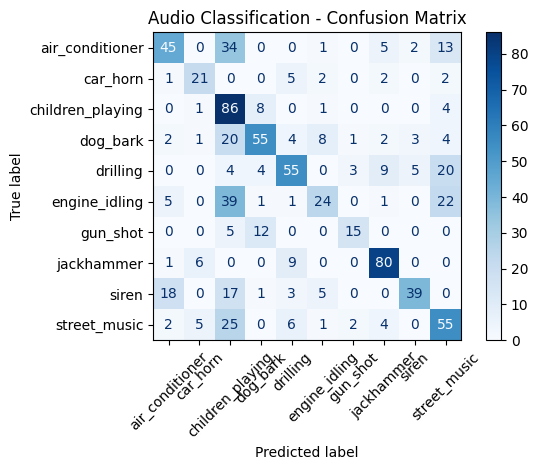

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(12, 9))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=list(range(10)),
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Audio Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

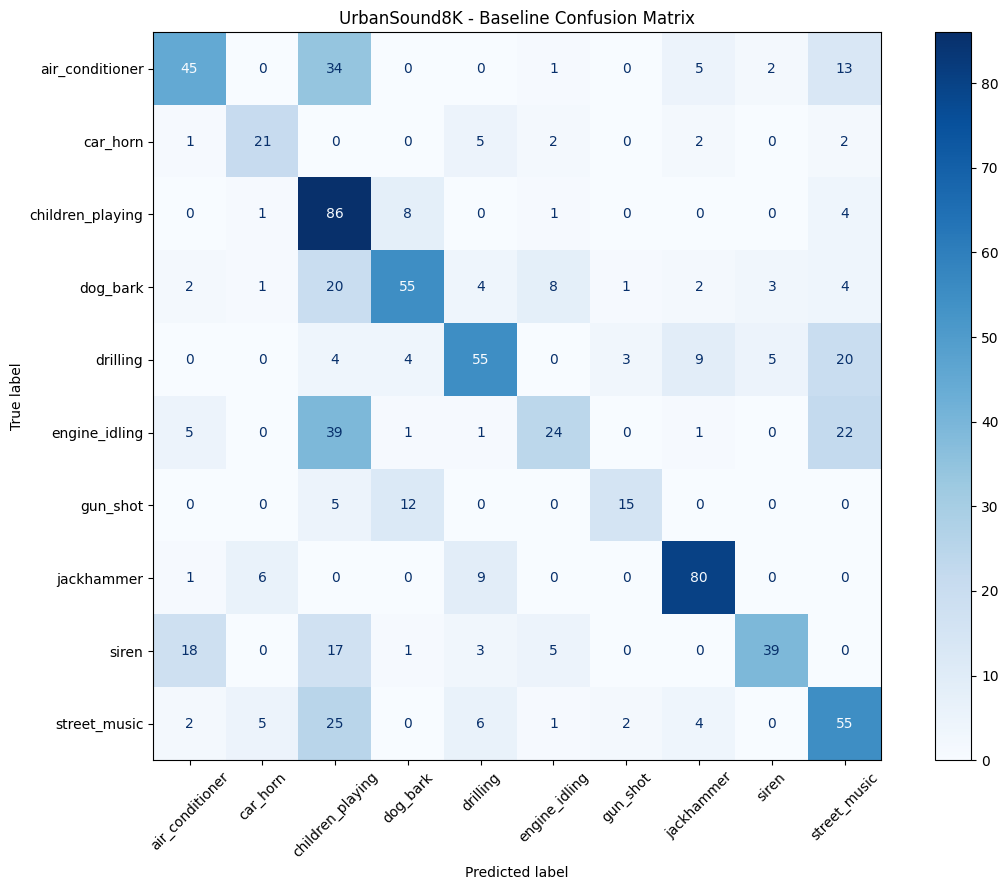

Confusion matrix saved successfully!
Location: /content/drive/MyDrive/Audio_Classification_Project/baseline_confusion_matrix.png


In [25]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import os

fig, ax = plt.subplots(figsize=(12, 9))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=list(range(10)),
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    ax=ax
)

ax.set_title("UrbanSound8K - Baseline Confusion Matrix")

plt.tight_layout()

save_path = os.path.join(
    project_dir,
    "baseline_confusion_matrix.png"
)

fig.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print("Confusion matrix saved successfully!")
print("Location:", save_path)

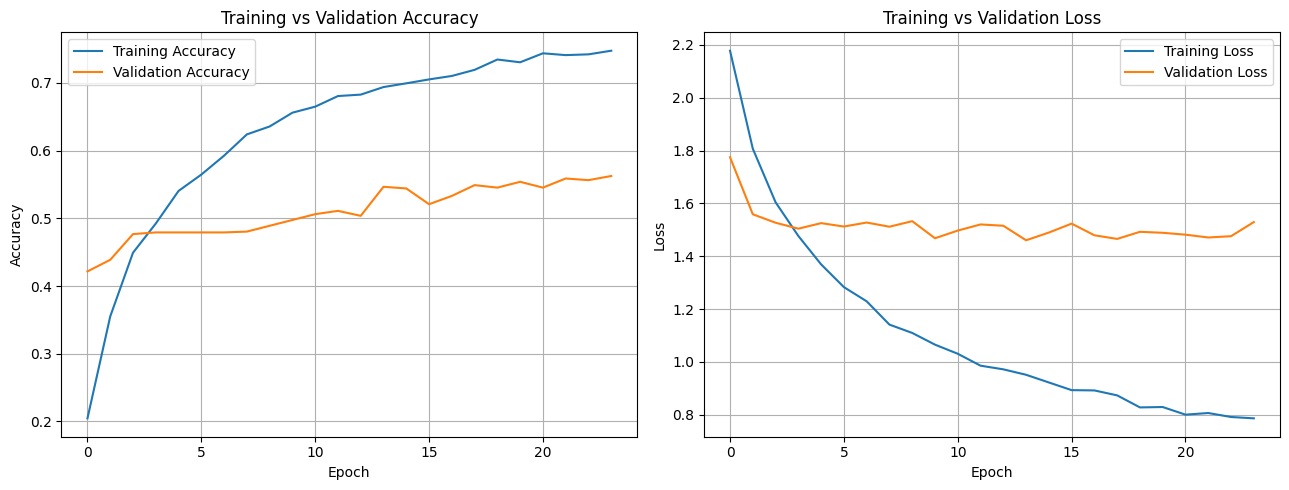

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy
axes[0].plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(
    history.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Improve the 40-feature architecture

Compare model designs using validation accuracy.


In [27]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.regularizers import l2

tf.keras.utils.set_random_seed(42)

improved_model = Sequential([
    Input(shape=(40,)),

    Dense(128, activation="relu",
          kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation="relu",
          kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

improved_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,922 (58.29 KB)

 Trainable params: 14,538 (56.79 KB)

 Non-trainable params: 384 (1.50 KB)

In [28]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

early_stop_improved = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

history_improved = improved_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop_improved, reduce_lr],
    verbose=1
)

print("\nImproved model training completed!")
print("Epochs trained:", len(history_improved.history["loss"]))

best_epoch = int(
    np.argmin(history_improved.history["val_loss"])
) + 1

val_loss_improved, val_acc_improved = improved_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print("Best epoch:", best_epoch)
print(f"Validation accuracy: {val_acc_improved * 100:.2f}%")
print(f"Validation loss: {val_loss_improved:.4f}")

Epoch 1/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3711 - loss: 2.0754 - val_accuracy: 0.4779 - val_loss: 1.6705 - learning_rate: 0.0010
Epoch 2/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5562 - loss: 1.4720 - val_accuracy: 0.5049 - val_loss: 1.6104 - learning_rate: 0.0010
Epoch 3/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6355 - loss: 1.2604 - val_accuracy: 0.5012 - val_loss: 1.5938 - learning_rate: 0.0010
Epoch 4/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6741 - loss: 1.1336 - val_accuracy: 0.5159 - val_loss: 1.5717 - learning_rate: 0.0010
Epoch 5/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6968 - loss: 1.0535 - val_accuracy: 0.5343 - val_loss: 1.6126 - learning_rate: 0.0010
Epoch 6/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7165 - loss: 0.9821 - val_accuracy: 0.5417 - val_loss: 1.5983 - learning_rate: 0.0010
Epoch 7/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7378 - loss: 0.

In [29]:

import numpy as np

val_acc_history = history_improved.history["val_accuracy"]
val_loss_history = history_improved.history["val_loss"]

best_acc_epoch = np.argmax(val_acc_history)
best_loss_epoch = np.argmin(val_loss_history)

print("BEST VALIDATION ACCURACY")
print("-" * 35)
print("Epoch:", best_acc_epoch + 1)
print(f"Accuracy: {val_acc_history[best_acc_epoch] * 100:.2f}%")
print(f"Loss: {val_loss_history[best_acc_epoch]:.4f}")

print("\nLOWEST VALIDATION LOSS")
print("-" * 35)
print("Epoch:", best_loss_epoch + 1)
print(f"Accuracy: {val_acc_history[best_loss_epoch] * 100:.2f}%")
print(f"Loss: {val_loss_history[best_loss_epoch]:.4f}")

BEST VALIDATION ACCURACY
-----------------------------------
Epoch: 17
Accuracy: 59.19%
Loss: 1.6538

LOWEST VALIDATION LOSS
-----------------------------------
Epoch: 4
Accuracy: 51.59%
Loss: 1.5717


In [30]:
import tensorflow as tf
import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Create a fresh copy of the improved architecture
tf.keras.utils.set_random_seed(42)

accuracy_model = tf.keras.models.clone_model(improved_model)

accuracy_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best model based on validation accuracy
checkpoint_path = os.path.join(
    project_dir,
    "best_validation_accuracy_model.keras"
)

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stop_accuracy = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=15,
    restore_best_weights=True
)

reduce_lr_accuracy = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

print("New model ready!")
print("Checkpoint location:", checkpoint_path)
print("Monitoring: Validation Accuracy")

New model ready!
Checkpoint location: /content/drive/MyDrive/Audio_Classification_Project/best_validation_accuracy_model.keras
Monitoring: Validation Accuracy


In [31]:
# Train the new model
history_accuracy = accuracy_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[
        checkpoint,
        early_stop_accuracy,
        reduce_lr_accuracy
    ],
    verbose=1
)

print("\nTraining completed!")
print("Epochs trained:", len(history_accuracy.history["loss"]))

# Find the best validation accuracy
best_epoch_accuracy = (
    np.argmax(history_accuracy.history["val_accuracy"]) + 1
)

best_val_accuracy = max(
    history_accuracy.history["val_accuracy"]
)

# Evaluate restored best weights
final_val_loss, final_val_accuracy = accuracy_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print("\nFINAL RESULTS")
print("-" * 35)
print("Best epoch:", best_epoch_accuracy)
print(f"Best validation accuracy: {best_val_accuracy * 100:.2f}%")
print(f"Restored validation accuracy: {final_val_accuracy * 100:.2f}%")
print(f"Restored validation loss: {final_val_loss:.4f}")

Epoch 1/100
203/222 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2575 - loss: 2.5244
Epoch 1: val_accuracy improved from None to 0.47794, saving model to /content/drive/MyDrive/Audio_Classification_Project/best_validation_accuracy_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Audio_Classification_Project/best_validation_accuracy_model.keras
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.3711 - loss: 2.0754 - val_accuracy: 0.4779 - val_loss: 1.6705 - learning_rate: 0.0010
Epoch 2/100
212/222 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5250 - loss: 1.5530
Epoch 2: val_accuracy improved from 0.47794 to 0.50490, saving model to /content/drive/MyDrive/Audio_Classification_Project/best_validation_accuracy_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Audio_Classification_Project/best_validation_accuracy_model.keras
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5562 - loss: 1.4720 - val_accuracy: 0.5049 - val_loss: 1.6104 -

In [32]:
import os
import tensorflow as tf

checkpoint_path = os.path.join(
    project_dir,
    "best_validation_accuracy_model.keras"
)

# Load the saved model
best_model = tf.keras.models.load_model(checkpoint_path)

# Evaluate on validation data only
saved_val_loss, saved_val_acc = best_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print(f"Saved model validation accuracy: {saved_val_acc * 100:.2f}%")
print(f"Saved model validation loss: {saved_val_loss:.4f}")

Checkpoint exists: True
Saved model validation accuracy: 59.19%
Saved model validation loss: 1.6538


In [33]:
import numpy as np
from sklearn.metrics import classification_report

# Predict validation samples
val_predictions = best_model.predict(
    X_val,
    verbose=0
)

# Convert probabilities to class predictions
y_val_pred = np.argmax(val_predictions, axis=1)

# Generate classification report
print("IMPROVED MODEL - VALIDATION REPORT")
print("-" * 50)

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=np.arange(10),
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

IMPROVED MODEL - VALIDATION REPORT
--------------------------------------------------
                  precision    recall  f1-score   support

 air_conditioner      0.306     0.110     0.162       100
        car_horn      0.429     0.750     0.545        32
children_playing      0.629     0.660     0.644       100
        dog_bark      0.648     0.590     0.618       100
        drilling      0.658     0.500     0.568       100
   engine_idling      0.653     0.888     0.752        89
        gun_shot      0.550     0.355     0.431        31
      jackhammer      0.600     0.659     0.628        82
           siren      0.859     0.963     0.908        82
    street_music      0.388     0.500     0.437       100

        accuracy                          0.592       816
       macro avg      0.572     0.597     0.569       816
    weighted avg      0.578     0.592     0.572       816



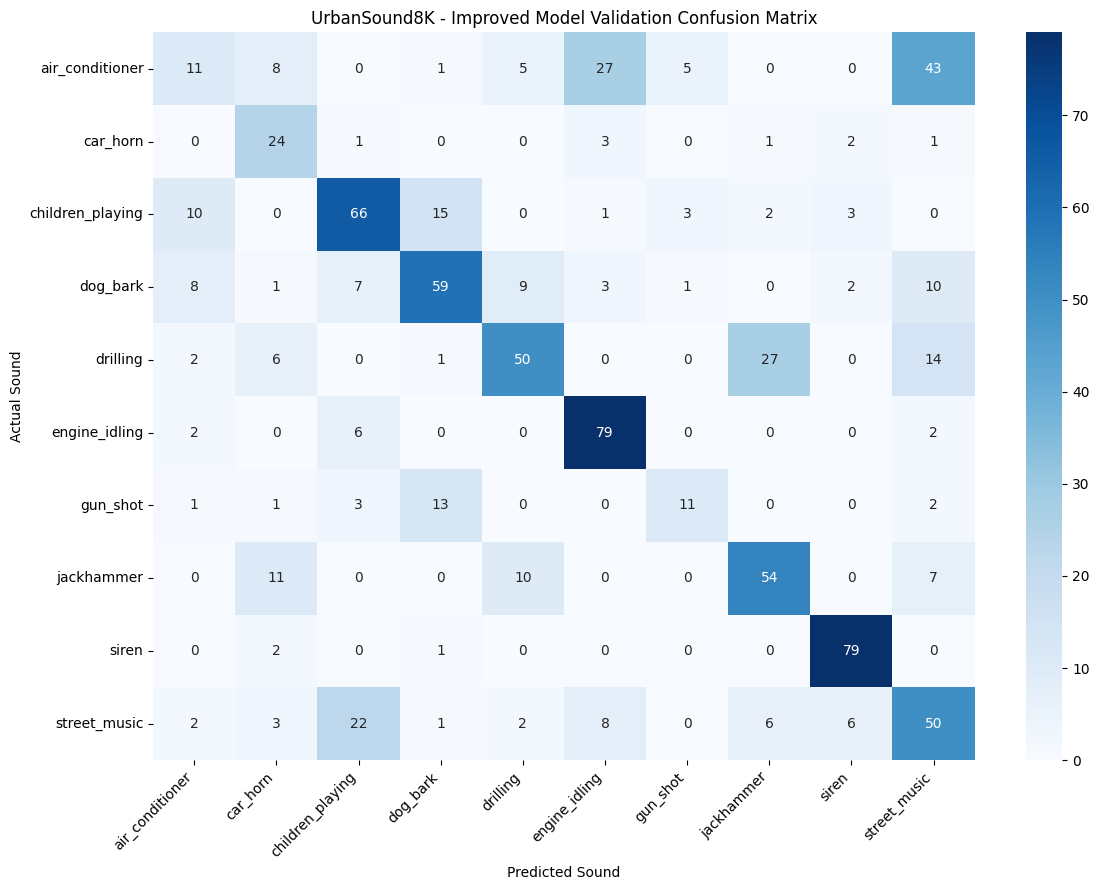

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_improved = confusion_matrix(
    y_val,
    y_val_pred,
    labels=np.arange(10)
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_improved,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("UrbanSound8K - Improved Model Validation Confusion Matrix")
plt.xlabel("Predicted Sound")
plt.ylabel("Actual Sound")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{project_dir}/improved_validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Engineer richer 86-dimensional audio features

Compute 40 MFCC means, 40 MFCC standard deviations, and summary statistics for spectral centroid, zero-crossing rate, and RMS energy.


In [35]:
import librosa
import numpy as np

def extract_richer_features(sample):
    audio_data = sample["audio"].get_all_samples()

    audio = audio_data.data.numpy()
    sr = audio_data.sample_rate

    if audio.ndim > 1:
        audio = np.mean(audio, axis=0)

    audio = audio.astype(np.float32)

    # MFCC features
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    # Spectral centroid
    centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )

    # Zero-crossing rate
    zcr = librosa.feature.zero_crossing_rate(audio)

    # RMS energy
    rms = librosa.feature.rms(y=audio)

    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        [np.mean(centroid), np.std(centroid)],
        [np.mean(zcr), np.std(zcr)],
        [np.mean(rms), np.std(rms)]
    ])

    return features.astype(np.float32)


# Test on one recording
sample = next(iter(dataset))

features = extract_richer_features(sample)

print("Feature shape:", features.shape)
print("Number of features:", len(features))
print("All values finite:", np.isfinite(features).all())

Feature shape: (86,)
Number of features: 86
All values finite: True


In [36]:
import os
import numpy as np
from tqdm.auto import tqdm

batch_size = 250
batch_number = 1

X_batch = []
y_batch = []
fold_batch = []

total_processed = 0

for sample in tqdm(dataset, total=8732):

    # Extract 86 audio features
    features = extract_richer_features(sample)

    # Read label and original UrbanSound8K fold
    label = int(sample["classID"])
    fold = int(sample["fold"])

    X_batch.append(features)
    y_batch.append(label)
    fold_batch.append(fold)

    total_processed += 1

    # Save each complete batch
    if len(X_batch) == batch_size:

        batch_path = os.path.join(
            project_dir,
            f"rich_features_batch_{batch_number:03d}.npz"
        )

        np.savez_compressed(
            batch_path,
            X=np.array(X_batch, dtype=np.float32),
            y=np.array(y_batch),
            folds=np.array(fold_batch)
        )

        print(
            f"Saved batch {batch_number}: "
            f"{total_processed} recordings processed"
        )

        batch_number += 1
        X_batch = []
        y_batch = []
        fold_batch = []

# Save the final incomplete batch
if len(X_batch) > 0:

    batch_path = os.path.join(
        project_dir,
        f"rich_features_batch_{batch_number:03d}.npz"
    )

    np.savez_compressed(
        batch_path,
        X=np.array(X_batch, dtype=np.float32),
        y=np.array(y_batch),
        folds=np.array(fold_batch)
    )

    print(f"Saved final batch {batch_number}")

print("\nFeature extraction completed!")
print("Total recordings processed:", total_processed)
print("Total batches saved:", batch_number)

  0%|          | 0/8732 [00:00<?, ?it/s]

Saved batch 1: 250 recordings processed
Saved batch 2: 500 recordings processed
Saved batch 3: 750 recordings processed
Saved batch 4: 1000 recordings processed
Saved batch 5: 1250 recordings processed
Saved batch 6: 1500 recordings processed
Saved batch 7: 1750 recordings processed
Saved batch 8: 2000 recordings processed
Saved batch 9: 2250 recordings processed
Saved batch 10: 2500 recordings processed
Saved batch 11: 2750 recordings processed


/usr/local/lib/python3.13/dist-packages/librosa/feature/spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)
/usr/local/lib/python3.13/dist-packages/librosa/feature/spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)
/usr/local/lib/python3.13/dist-packages/librosa/feature/spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)
/usr/local/lib/python3.13/dist-packages/librosa/feature/spectral.py:2148: UserWarning: Empty filters de

Saved batch 12: 3000 recordings processed
Saved batch 13: 3250 recordings processed
Saved batch 14: 3500 recordings processed
Saved batch 15: 3750 recordings processed
Saved batch 16: 4000 recordings processed
Saved batch 17: 4250 recordings processed
Saved batch 18: 4500 recordings processed
Saved batch 19: 4750 recordings processed
Saved batch 20: 5000 recordings processed
Saved batch 21: 5250 recordings processed
Saved batch 22: 5500 recordings processed
Saved batch 23: 5750 recordings processed
Saved batch 24: 6000 recordings processed
Saved batch 25: 6250 recordings processed
Saved batch 26: 6500 recordings processed
Saved batch 27: 6750 recordings processed
Saved batch 28: 7000 recordings processed
Saved batch 29: 7250 recordings processed
Saved batch 30: 7500 recordings processed
Saved batch 31: 7750 recordings processed
Saved batch 32: 8000 recordings processed
Saved batch 33: 8250 recordings processed
Saved batch 34: 8500 recordings processed
Saved final batch 35

Feature extr

## Combine rich features and standardize

Verify batch completeness and fit a new scaler using only training-fold data.


In [37]:
import os
import glob
import numpy as np

# Find all richer-feature batches
batch_files = sorted(
    glob.glob(
        os.path.join(
            project_dir,
            "rich_features_batch_*.npz"
        )
    )
)

print("Batch files found:", len(batch_files))

X_parts = []
y_parts = []
fold_parts = []

for file in batch_files:
    with np.load(file) as data:
        X_parts.append(data["X"])
        y_parts.append(data["y"])
        fold_parts.append(data["folds"])

# Combine batches
X_rich = np.concatenate(X_parts, axis=0)
y_rich = np.concatenate(y_parts, axis=0)
folds_rich = np.concatenate(fold_parts, axis=0)

# Validate
print("\nDATASET VERIFICATION")
print("-" * 40)
print("Feature shape:", X_rich.shape)
print("Label shape:", y_rich.shape)
print("Fold shape:", folds_rich.shape)
print("All values finite:", np.isfinite(X_rich).all())
print("Unique classes:", np.unique(y_rich))
print("Unique folds:", np.unique(folds_rich))

# Verify alignment with original dataset
print("Labels match original:", np.array_equal(y_rich, y_all))
print("Folds match original:", np.array_equal(folds_rich, folds_all))

# Save combined dataset only after validation
if (
    X_rich.shape == (8732, 86)
    and np.isfinite(X_rich).all()
    and np.array_equal(y_rich, y_all)
    and np.array_equal(folds_rich, folds_all)
):
    combined_path = os.path.join(
        project_dir,
        "urbansound8k_rich_features_complete.npz"
    )

    np.savez_compressed(
        combined_path,
        X=X_rich,
        y=y_rich,
        folds=folds_rich
    )

    print("\nCombined dataset saved successfully!")
else:
    print("\nVerification failed. Dataset not saved.")

Batch files found: 35

DATASET VERIFICATION
----------------------------------------
Feature shape: (8732, 86)
Label shape: (8732,)
Fold shape: (8732,)
All values finite: True
Unique classes: [0 1 2 3 4 5 6 7 8 9]
Unique folds: [ 1  2  3  4  5  6  7  8  9 10]
Labels match original: True
Folds match original: True

Combined dataset saved successfully!


In [38]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import joblib
import os

# Preserve original UrbanSound8K fold assignments
rich_train_mask = folds_rich <= 8
rich_val_mask = folds_rich == 9
rich_test_mask = folds_rich == 10

# Split features and labels
X_train_rich = X_rich[rich_train_mask]
y_train_rich = y_rich[rich_train_mask]

X_val_rich = X_rich[rich_val_mask]
y_val_rich = y_rich[rich_val_mask]

X_test_rich = X_rich[rich_test_mask]
y_test_rich = y_rich[rich_test_mask]

# Fit scaler ONLY on training data
rich_scaler = StandardScaler()

X_train_rich = rich_scaler.fit_transform(
    X_train_rich
).astype(np.float32)

X_val_rich = rich_scaler.transform(
    X_val_rich
).astype(np.float32)

X_test_rich = rich_scaler.transform(
    X_test_rich
).astype(np.float32)

# Save scaler for future predictions
scaler_path = os.path.join(
    project_dir,
    "rich_feature_scaler.pkl"
)

joblib.dump(rich_scaler, scaler_path)

# Verify results
print("RICH FEATURE DATASET")
print("-" * 40)

print("Training:", X_train_rich.shape)
print("Validation:", X_val_rich.shape)
print("Testing:", X_test_rich.shape)

print("\nTraining mean:", round(float(X_train_rich.mean()), 5))
print("Training std:", round(float(X_train_rich.std()), 5))

print("All values finite:",
      np.isfinite(X_train_rich).all()
      and np.isfinite(X_val_rich).all()
      and np.isfinite(X_test_rich).all())

print("\nScaler saved successfully!")

RICH FEATURE DATASET
----------------------------------------
Training: (7079, 86)
Validation: (816, 86)
Testing: (837, 86)

Training mean: -0.0
Training std: 1.0
All values finite: True

Scaler saved successfully!


## Train the rich-feature model

Evaluate the 86-feature model using the validation fold.


In [39]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build model for 86 audio features
rich_model = Sequential([
    Input(shape=(86,)),

    Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    Dropout(0.3),

    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

# Compile
rich_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
rich_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 128)            │        11,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,810 (81.29 KB)

 Trainable params: 20,426 (79.79 KB)

 Non-trainable params: 384 (1.50 KB)

In [40]:
import os
import numpy as np
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Save the best 86-feature model
rich_checkpoint_path = os.path.join(
    project_dir,
    "best_rich_feature_model.keras"
)

rich_checkpoint = ModelCheckpoint(
    rich_checkpoint_path,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

rich_early_stop = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=15,
    restore_best_weights=True
)

rich_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

# Train the model
history_rich = rich_model.fit(
    X_train_rich,
    y_train_rich,
    validation_data=(X_val_rich, y_val_rich),
    epochs=100,
    batch_size=32,
    callbacks=[
        rich_checkpoint,
        rich_early_stop,
        rich_reduce_lr
    ],
    verbose=1
)

# Identify best epoch
best_rich_epoch = (
    np.argmax(history_rich.history["val_accuracy"]) + 1
)

# Evaluate restored weights on validation data
rich_val_loss, rich_val_acc = rich_model.evaluate(
    X_val_rich,
    y_val_rich,
    verbose=0
)

print("\nRICH FEATURE MODEL RESULTS")
print("-" * 40)
print("Epochs trained:", len(history_rich.history["loss"]))
print("Best epoch:", best_rich_epoch)
print(f"Validation accuracy: {rich_val_acc * 100:.2f}%")
print(f"Validation loss: {rich_val_loss:.4f}")
print("Model saved to:", rich_checkpoint_path)

Epoch 1/100
199/222 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3493 - loss: 2.2033
Epoch 1: val_accuracy improved from None to 0.64216, saving model to /content/drive/MyDrive/Audio_Classification_Project/best_rich_feature_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Audio_Classification_Project/best_rich_feature_model.keras
222/222 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4927 - loss: 1.7226 - val_accuracy: 0.6422 - val_loss: 1.3437 - learning_rate: 0.0010
Epoch 2/100
221/222 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6704 - loss: 1.1957
Epoch 2: val_accuracy improved from 0.64216 to 0.65686, saving model to /content/drive/MyDrive/Audio_Classification_Project/best_rich_feature_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Audio_Classification_Project/best_rich_feature_model.keras
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6901 - loss: 1.1306 - val_accuracy: 0.6569 - val_loss: 1.3311 - learning_rate: 0.0010
Epoch

In [41]:
import os
import tensorflow as tf

# Load the best saved rich-feature model
saved_rich_model = tf.keras.models.load_model(
    rich_checkpoint_path
)

# Evaluate on validation data
saved_rich_loss, saved_rich_acc = saved_rich_model.evaluate(
    X_val_rich,
    y_val_rich,
    verbose=0
)

print("RICH FEATURE MODEL VERIFICATION")
print("-" * 40)

print(
    "Checkpoint exists:",
    os.path.exists(rich_checkpoint_path)
)

print(
    f"Saved validation accuracy: {saved_rich_acc * 100:.2f}%"
)

print(
    f"Saved validation loss: {saved_rich_loss:.4f}"
)

print(
    "Model input shape:",
    saved_rich_model.input_shape
)

RICH FEATURE MODEL VERIFICATION
----------------------------------------
Checkpoint exists: True
Saved validation accuracy: 69.12%
Saved validation loss: 1.5069
Model input shape: (None, 86)


In [42]:
import numpy as np
from sklearn.metrics import classification_report

# Predict using the best saved 86-feature model
rich_val_probabilities = saved_rich_model.predict(
    X_val_rich,
    verbose=0
)

rich_val_predictions = np.argmax(
    rich_val_probabilities,
    axis=1
)

# Generate classification report
print("86-FEATURE MODEL - VALIDATION REPORT")
print("-" * 55)

print(
    classification_report(
        y_val_rich,
        rich_val_predictions,
        labels=np.arange(10),
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

86-FEATURE MODEL - VALIDATION REPORT
-------------------------------------------------------
                  precision    recall  f1-score   support

 air_conditioner      0.528     0.190     0.279       100
        car_horn      0.532     0.781     0.633        32
children_playing      0.622     0.790     0.696       100
        dog_bark      0.592     0.740     0.658       100
        drilling      0.812     0.560     0.663       100
   engine_idling      0.750     0.843     0.794        89
        gun_shot      0.826     0.613     0.704        31
      jackhammer      0.707     0.793     0.747        82
           siren      0.976     0.976     0.976        82
    street_music      0.626     0.720     0.670       100

        accuracy                          0.691       816
       macro avg      0.697     0.701     0.682       816
    weighted avg      0.693     0.691     0.675       816



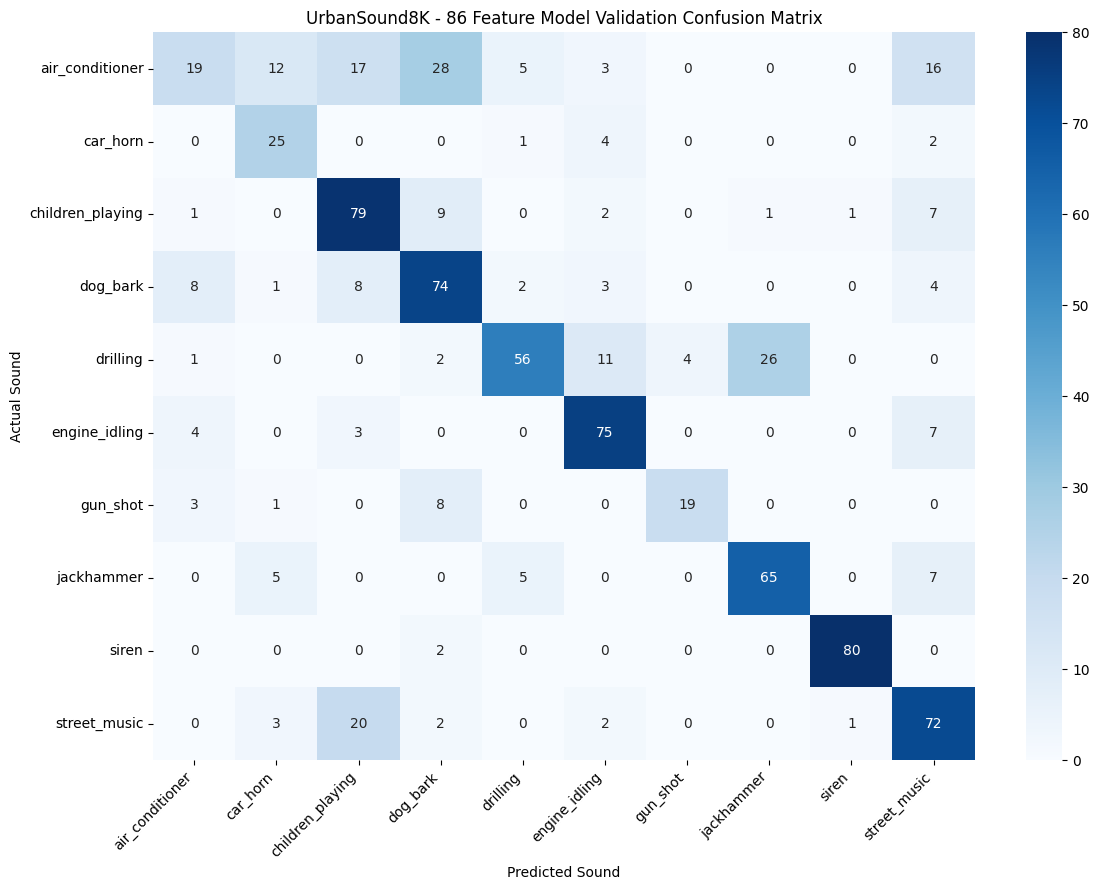


TOP 5 MISCLASSIFICATIONS
---------------------------------------------
air_conditioner → dog_bark: 28 recordings
drilling → jackhammer: 26 recordings
street_music → children_playing: 20 recordings
air_conditioner → children_playing: 17 recordings
air_conditioner → street_music: 16 recordings


In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm_rich = confusion_matrix(
    y_val_rich,
    rich_val_predictions,
    labels=np.arange(10)
)

# Plot
plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_rich,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("UrbanSound8K - 86 Feature Model Validation Confusion Matrix")
plt.xlabel("Predicted Sound")
plt.ylabel("Actual Sound")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save to Google Drive
plt.savefig(
    f"{project_dir}/rich_feature_validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Identify the five largest misclassification patterns
errors = cm_rich.copy()
np.fill_diagonal(errors, 0)

error_pairs = np.argsort(errors.ravel())[::-1][:5]

print("\nTOP 5 MISCLASSIFICATIONS")
print("-" * 45)

for index in error_pairs:
    actual, predicted = np.unravel_index(index, errors.shape)

    print(
        f"{class_names[actual]} → "
        f"{class_names[predicted]}: "
        f"{errors[actual, predicted]} recordings"
    )

## Train the final regularized model

Use stronger dropout and L2 regularization, with validation-based checkpointing and early stopping.


In [44]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2

# Set random seed
tf.keras.utils.set_random_seed(42)

# Build regularized model
regularized_model = Sequential([
    Input(shape=(86,)),

    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.005)
    ),
    BatchNormalization(),
    Dropout(0.5),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.005)
    ),
    BatchNormalization(),
    Dropout(0.4),

    Dense(10, activation="softmax")
])

# Compile model
regularized_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
regularized_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 64)             │         5,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,362 (32.66 KB)

 Trainable params: 8,170 (31.91 KB)

 Non-trainable params: 192 (768.00 B)

In [45]:
import os
import numpy as np

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Save separately to preserve our best previous model
regularized_checkpoint_path = os.path.join(
    project_dir,
    "best_regularized_model.keras"
)

regularized_checkpoint = ModelCheckpoint(
    regularized_checkpoint_path,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

regularized_early_stop = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=15,
    restore_best_weights=True
)

regularized_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

# Train the model
history_regularized = regularized_model.fit(
    X_train_rich,
    y_train_rich,
    validation_data=(X_val_rich, y_val_rich),
    epochs=100,
    batch_size=32,
    callbacks=[
        regularized_checkpoint,
        regularized_early_stop,
        regularized_reduce_lr
    ],
    verbose=1
)

# Find the best epoch
best_reg_epoch = (
    np.argmax(history_regularized.history["val_accuracy"]) + 1
)

# Evaluate restored model on validation data
reg_val_loss, reg_val_acc = regularized_model.evaluate(
    X_val_rich,
    y_val_rich,
    verbose=0
)

print("\nREGULARIZED MODEL RESULTS")
print("-" * 40)
print("Epochs trained:", len(history_regularized.history["loss"]))
print("Best epoch:", best_reg_epoch)
print(f"Validation accuracy: {reg_val_acc * 100:.2f}%")
print(f"Validation loss: {reg_val_loss:.4f}")
print("Model saved to:", regularized_checkpoint_path)

Epoch 1/100
196/222 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1744 - loss: 3.2595
Epoch 1: val_accuracy improved from None to 0.45588, saving model to /content/drive/MyDrive/Audio_Classification_Project/best_regularized_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Audio_Classification_Project/best_regularized_model.keras
222/222 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.2644 - loss: 2.7785 - val_accuracy: 0.4559 - val_loss: 2.0271 - learning_rate: 0.0010
Epoch 2/100
206/222 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4271 - loss: 2.1585
Epoch 2: val_accuracy improved from 0.45588 to 0.50980, saving model to /content/drive/MyDrive/Audio_Classification_Project/best_regularized_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Audio_Classification_Project/best_regularized_model.keras
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4587 - loss: 2.0591 - val_accuracy: 0.5098 - val_loss: 1.7959 - learning_rate: 0.0010
Epoch 3/1

In [46]:
import os
import tensorflow as tf

# Load the saved regularized model
saved_regularized_model = tf.keras.models.load_model(
    regularized_checkpoint_path
)

# Evaluate on validation data only
saved_reg_loss, saved_reg_acc = saved_regularized_model.evaluate(
    X_val_rich,
    y_val_rich,
    verbose=0
)

print("REGULARIZED MODEL VERIFICATION")
print("-" * 40)

print(
    "Checkpoint exists:",
    os.path.exists(regularized_checkpoint_path)
)

print(
    f"Saved validation accuracy: {saved_reg_acc * 100:.2f}%"
)

print(
    f"Saved validation loss: {saved_reg_loss:.4f}"
)

print(
    "Model input shape:",
    saved_regularized_model.input_shape
)

REGULARIZED MODEL VERIFICATION
----------------------------------------
Checkpoint exists: True
Saved validation accuracy: 70.71%
Saved validation loss: 1.2273
Model input shape: (None, 86)


In [47]:
import numpy as np
from sklearn.metrics import classification_report

# Predict validation recordings
reg_val_probabilities = saved_regularized_model.predict(
    X_val_rich,
    verbose=0
)

# Convert probabilities into class predictions
reg_val_predictions = np.argmax(
    reg_val_probabilities,
    axis=1
)

# Generate classification report
print("REGULARIZED MODEL - VALIDATION REPORT")
print("-" * 55)

print(
    classification_report(
        y_val_rich,
        reg_val_predictions,
        labels=np.arange(10),
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

REGULARIZED MODEL - VALIDATION REPORT
-------------------------------------------------------
                  precision    recall  f1-score   support

 air_conditioner      0.487     0.190     0.273       100
        car_horn      0.641     0.781     0.704        32
children_playing      0.698     0.900     0.786       100
        dog_bark      0.651     0.690     0.670       100
        drilling      0.750     0.510     0.607       100
   engine_idling      0.766     0.955     0.850        89
        gun_shot      1.000     0.645     0.784        31
      jackhammer      0.641     0.805     0.714        82
           siren      0.952     0.963     0.958        82
    street_music      0.619     0.730     0.670       100

        accuracy                          0.707       816
       macro avg      0.720     0.717     0.702       816
    weighted avg      0.699     0.707     0.686       816



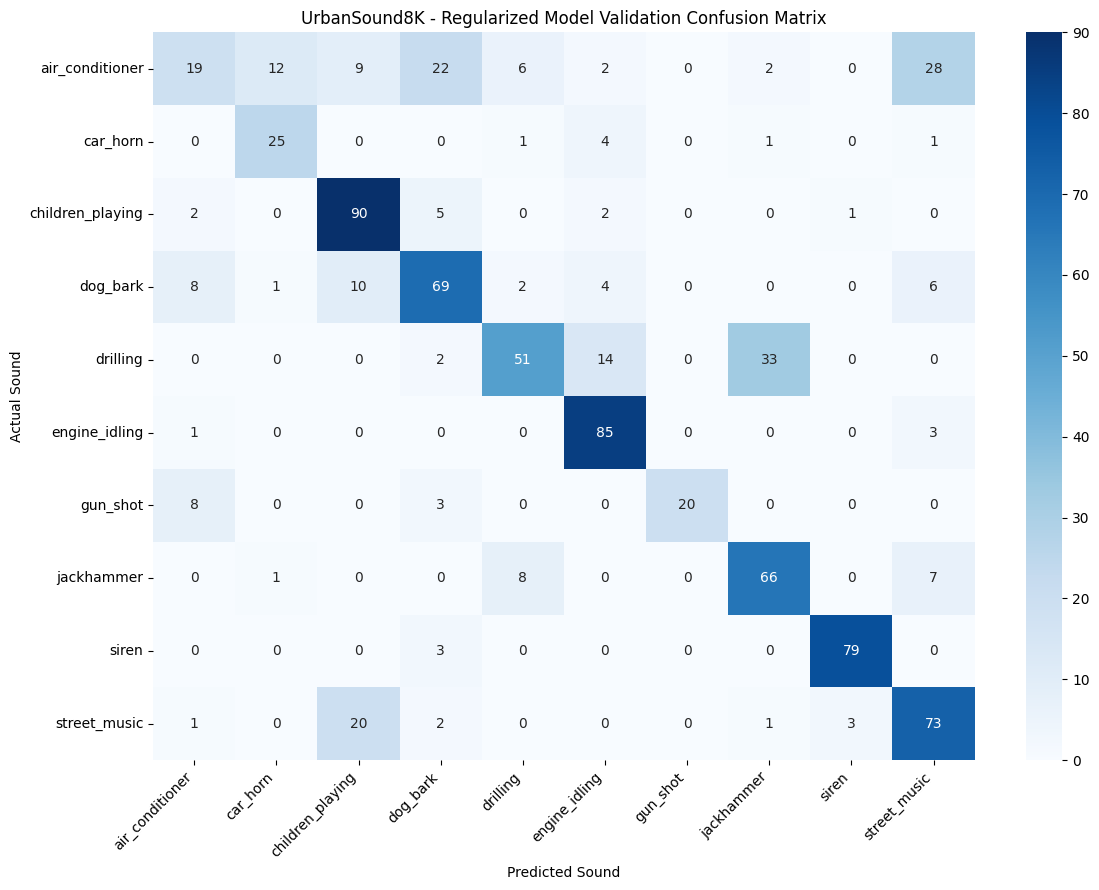


TOP 5 MISCLASSIFICATIONS
---------------------------------------------
drilling → jackhammer: 33 recordings
air_conditioner → street_music: 28 recordings
air_conditioner → dog_bark: 22 recordings
street_music → children_playing: 20 recordings
drilling → engine_idling: 14 recordings


In [48]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm_regularized = confusion_matrix(
    y_val_rich,
    reg_val_predictions,
    labels=np.arange(10)
)

# Plot confusion matrix
plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_regularized,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("UrbanSound8K - Regularized Model Validation Confusion Matrix")
plt.xlabel("Predicted Sound")
plt.ylabel("Actual Sound")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save to Google Drive
plt.savefig(
    os.path.join(
        project_dir,
        "regularized_validation_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Find the five largest misclassification patterns
errors = cm_regularized.copy()
np.fill_diagonal(errors, 0)

top_errors = np.argsort(errors.ravel())[::-1][:5]

print("\nTOP 5 MISCLASSIFICATIONS")
print("-" * 45)

for index in top_errors:
    actual, predicted = np.unravel_index(
        index,
        errors.shape
    )

    print(
        f"{class_names[actual]} → "
        f"{class_names[predicted]}: "
        f"{errors[actual, predicted]} recordings"
    )

## Final held-out test evaluation

Report accuracy, per-class precision/recall/F1, and the confusion matrix for fold 10. These are results for one fold split, not 10-fold cross-validation.


In [49]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

# Predict on the held-out test set
test_probabilities = saved_regularized_model.predict(
    X_test_rich,
    verbose=0
)

test_predictions = np.argmax(
    test_probabilities,
    axis=1
)

# Calculate final metrics
final_test_accuracy = accuracy_score(
    y_test_rich,
    test_predictions
)

final_test_macro_f1 = f1_score(
    y_test_rich,
    test_predictions,
    average="macro"
)

final_test_weighted_f1 = f1_score(
    y_test_rich,
    test_predictions,
    average="weighted"
)

print("FINAL HELD-OUT TEST RESULTS")
print("-" * 45)
print(f"Test accuracy: {final_test_accuracy * 100:.2f}%")
print(f"Macro F1-score: {final_test_macro_f1:.4f}")
print(f"Weighted F1-score: {final_test_weighted_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print("-" * 45)

print(
    classification_report(
        y_test_rich,
        test_predictions,
        labels=np.arange(10),
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

FINAL HELD-OUT TEST RESULTS
---------------------------------------------
Test accuracy: 72.88%
Macro F1-score: 0.7520
Weighted F1-score: 0.7270

CLASSIFICATION REPORT
---------------------------------------------
                  precision    recall  f1-score   support

 air_conditioner      0.551     0.590     0.570       100
        car_horn      0.964     0.818     0.885        33
children_playing      0.601     0.950     0.736       100
        dog_bark      0.779     0.670     0.720       100
        drilling      0.680     0.510     0.583       100
   engine_idling      0.683     0.763     0.721        93
        gun_shot      0.968     0.938     0.952        32
      jackhammer      0.862     0.844     0.853        96
           siren      0.780     0.554     0.648        83
    street_music      0.874     0.830     0.851       100

        accuracy                          0.729       837
       macro avg      0.774     0.747     0.752       837
    weighted avg      0.743   

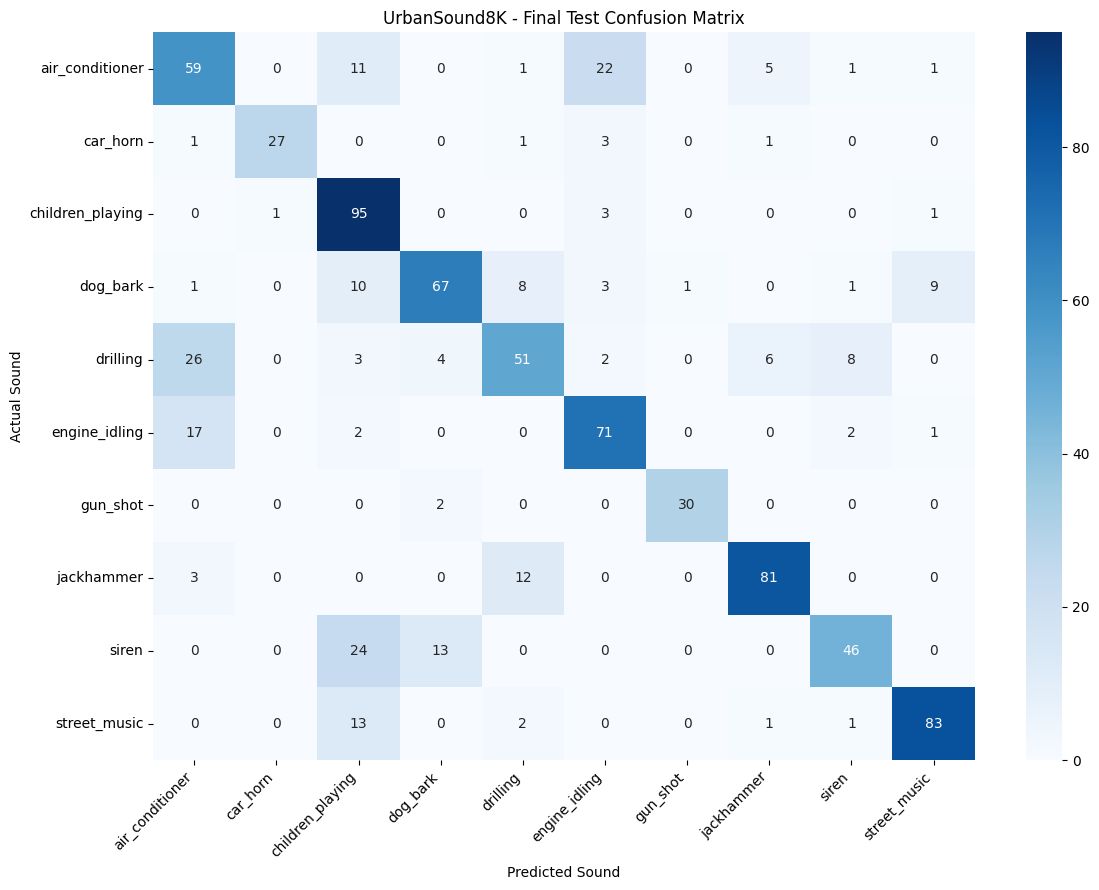

FINAL RESULTS SAVED SUCCESSFULLY!
----------------------------------------
1. final_evaluation_results.json
2. final_test_classification_report.txt
3. final_test_confusion_matrix.png


In [50]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Save final evaluation metrics
final_results = {
    "model": "Regularized Dense Neural Network",
    "dataset": "UrbanSound8K",
    "features": 86,
    "training_folds": list(range(1, 9)),
    "validation_fold": 9,
    "test_fold": 10,
    "test_samples": int(len(y_test_rich)),
    "validation_accuracy": float(saved_reg_acc),
    "test_accuracy": float(final_test_accuracy),
    "macro_f1": float(final_test_macro_f1),
    "weighted_f1": float(final_test_weighted_f1)
}

results_path = os.path.join(
    project_dir,
    "final_evaluation_results.json"
)

with open(results_path, "w") as f:
    json.dump(final_results, f, indent=4)

# Save classification report
report = classification_report(
    y_test_rich,
    test_predictions,
    labels=np.arange(10),
    target_names=class_names,
    digits=3,
    zero_division=0
)

report_path = os.path.join(
    project_dir,
    "final_test_classification_report.txt"
)

with open(report_path, "w") as f:
    f.write(report)

# Create and save final confusion matrix
cm_final = confusion_matrix(
    y_test_rich,
    test_predictions,
    labels=np.arange(10)
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("UrbanSound8K - Final Test Confusion Matrix")
plt.xlabel("Predicted Sound")
plt.ylabel("Actual Sound")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = os.path.join(
    project_dir,
    "final_test_confusion_matrix.png"
)

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

print("FINAL RESULTS SAVED SUCCESSFULLY!")
print("-" * 40)
print("1. final_evaluation_results.json")
print("2. final_test_classification_report.txt")
print("3. final_test_confusion_matrix.png")

## Prepare portfolio repository files

Create the repository folders, save the final model and scaler, generate reusable inference scripts, test the inference pipeline, and write the README.


In [51]:
import os

# Create GitHub-ready project folder
github_project_dir = os.path.join(
    project_dir,
    "UrbanSound8K_GitHub"
)

folders = [
    "src",
    "models",
    "results",
    "notebooks",
    "docs"
]

os.makedirs(github_project_dir, exist_ok=True)

for folder in folders:
    os.makedirs(
        os.path.join(github_project_dir, folder),
        exist_ok=True
    )

print("GITHUB PROJECT STRUCTURE")
print("-" * 40)

print("UrbanSound8K_GitHub/")

for folder in folders:
    print(f"    {folder}/")

print("\nProject folders created successfully!")

GITHUB PROJECT STRUCTURE
----------------------------------------
UrbanSound8K_GitHub/
    src/
    models/
    results/
    notebooks/
    docs/

Project folders created successfully!


In [52]:
import os
import shutil

# Files to organize
files_to_copy = {
    "best_regularized_model.keras": "models",
    "rich_feature_scaler.pkl": "models",
    "final_evaluation_results.json": "results",
    "final_test_classification_report.txt": "results",
    "final_test_confusion_matrix.png": "results",
    "regularized_validation_confusion_matrix.png": "results"
}

print("ORGANIZING GITHUB PROJECT FILES")
print("-" * 45)

for filename, destination_folder in files_to_copy.items():

    source_path = os.path.join(
        project_dir,
        filename
    )

    destination_path = os.path.join(
        github_project_dir,
        destination_folder,
        filename
    )

    if os.path.exists(source_path):

        shutil.copy2(
            source_path,
            destination_path
        )

        print(f"Copied: {filename}")

    else:
        print(f"NOT FOUND: {filename}")

print("\nFile organization completed!")

ORGANIZING GITHUB PROJECT FILES
---------------------------------------------
Copied: best_regularized_model.keras
Copied: rich_feature_scaler.pkl
Copied: final_evaluation_results.json
Copied: final_test_classification_report.txt
Copied: final_test_confusion_matrix.png
Copied: regularized_validation_confusion_matrix.png

File organization completed!


In [53]:
import os

feature_script = '''
import numpy as np
import librosa


def extract_features(audio, sr):
    """
    Extract 86 audio features:
    - 40 MFCC means
    - 40 MFCC standard deviations
    - Spectral centroid mean and std
    - Zero-crossing rate mean and std
    - RMS energy mean and std
    """

    audio = np.asarray(audio, dtype=np.float32)

    if audio.ndim > 1:
        audio = np.mean(audio, axis=0)

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )

    zcr = librosa.feature.zero_crossing_rate(audio)

    rms = librosa.feature.rms(y=audio)

    features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        [np.mean(centroid), np.std(centroid)],
        [np.mean(zcr), np.std(zcr)],
        [np.mean(rms), np.std(rms)]
    ])

    return features.astype(np.float32)


def extract_features_from_file(file_path):
    """
    Load an audio file and extract its 86 features.

    Preserve the original sample rate to match
    the feature extraction used during training.
    """

    audio, sr = librosa.load(
        file_path,
        sr=None,
        mono=True
    )

    return extract_features(audio, sr)
'''

script_path = os.path.join(
    github_project_dir,
    "src",
    "feature_extraction.py"
)

with open(script_path, "w", encoding="utf-8") as f:
    f.write(feature_script.strip() + "\n")

print("FEATURE EXTRACTION SCRIPT CREATED")
print("-" * 45)
print("File:", script_path)
print("Exists:", os.path.exists(script_path))

FEATURE EXTRACTION SCRIPT CREATED
---------------------------------------------
File: /content/drive/MyDrive/Audio_Classification_Project/UrbanSound8K_GitHub/src/feature_extraction.py
Exists: True


In [54]:
import os

prediction_script = '''
import os
import sys
import argparse

import joblib
import numpy as np
import tensorflow as tf

from feature_extraction import extract_features_from_file


CLASS_NAMES = [
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music"
]


def predict_audio(file_path):
    # Find the project root
    project_root = os.path.dirname(
        os.path.dirname(os.path.abspath(__file__))
    )

    model_path = os.path.join(
        project_root, "models", "best_regularized_model.keras"
    )

    scaler_path = os.path.join(
        project_root, "models", "rich_feature_scaler.pkl"
    )

    # Load trained model and scaler
    model = tf.keras.models.load_model(model_path)
    scaler = joblib.load(scaler_path)

    # Extract 86 features
    features = extract_features_from_file(file_path)

    if features.shape != (86,):
        raise ValueError("Expected exactly 86 audio features.")

    if not np.isfinite(features).all():
        raise ValueError("Audio features contain invalid values.")

    # Standardize using the training scaler
    features_scaled = scaler.transform(
        features.reshape(1, -1)
    ).astype(np.float32)

    # Predict sound category
    probabilities = model.predict(
        features_scaled, verbose=0
    )[0]

    predicted_class = int(np.argmax(probabilities))

    return CLASS_NAMES[predicted_class], float(
        probabilities[predicted_class]
    )


if __name__ == "__main__":
    parser = argparse.ArgumentParser(
        description="Classify an urban sound recording"
    )

    parser.add_argument(
        "audio_file",
        help="Path to an audio recording"
    )

    args = parser.parse_args()

    label, confidence = predict_audio(args.audio_file)

    print("\\nAUDIO CLASSIFICATION RESULT")
    print("-" * 40)
    print("Predicted sound:", label)
    print(f"Model probability: {confidence * 100:.2f}%")
'''

prediction_path = os.path.join(
    github_project_dir,
    "src",
    "predict.py"
)

with open(prediction_path, "w", encoding="utf-8") as f:
    f.write(prediction_script.strip() + "\n")

print("PREDICTION SCRIPT CREATED")
print("-" * 45)
print("File:", prediction_path)
print("Exists:", os.path.exists(prediction_path))

PREDICTION SCRIPT CREATED
---------------------------------------------
File: /content/drive/MyDrive/Audio_Classification_Project/UrbanSound8K_GitHub/src/predict.py
Exists: True


In [55]:
import os
import sys
import tempfile
import numpy as np
import soundfile as sf

# Make our prediction script importable
sys.path.insert(
    0,
    os.path.join(github_project_dir, "src")
)

from predict import predict_audio

# Get one recording from the streaming dataset
test_sample = next(iter(dataset))

audio_data = test_sample["audio"].get_all_samples()
audio = audio_data.data.numpy()
sample_rate = audio_data.sample_rate

# Convert to mono if necessary
if audio.ndim > 1:
    audio = np.mean(audio, axis=0)

audio = audio.astype(np.float32)

# Save a temporary WAV recording
with tempfile.TemporaryDirectory() as temp_dir:

    audio_path = os.path.join(
        temp_dir,
        "test_audio.wav"
    )

    sf.write(
        audio_path,
        audio,
        sample_rate,
        subtype="FLOAT"
    )

    # Predict using our GitHub script
    predicted_label, probability = predict_audio(
        audio_path
    )

    # Find the actual class
    actual_label = class_names[int(test_sample["classID"])]

    print("AUDIO PREDICTION TEST")
    print("-" * 45)
    print("Actual sound:", actual_label)
    print("Predicted sound:", predicted_label)
    print(f"Model probability: {probability * 100:.2f}%")
    print("Prediction correct:", predicted_label == actual_label)

AUDIO PREDICTION TEST
---------------------------------------------
Actual sound: dog_bark
Predicted sound: dog_bark
Model probability: 85.30%
Prediction correct: True


In [56]:
import os

requirements = """numpy>=1.26,<3
librosa>=0.11,<0.12
tensorflow>=2.16,<2.22
scikit-learn>=1.5,<1.8
joblib>=1.4,<2
soundfile>=0.12,<1
matplotlib>=3.8,<4
seaborn>=0.13,<0.14
datasets>=3,<6
"""

requirements_path = os.path.join(
    github_project_dir,
    "requirements.txt"
)

with open(requirements_path, "w", encoding="utf-8") as f:
    f.write(requirements)

print("REQUIREMENTS FILE CREATED")
print("-" * 45)
print("File:", requirements_path)
print("Exists:", os.path.exists(requirements_path))

print("\nFILE CONTENTS:")
print(requirements)

REQUIREMENTS FILE CREATED
---------------------------------------------
File: /content/drive/MyDrive/Audio_Classification_Project/UrbanSound8K_GitHub/requirements.txt
Exists: True

FILE CONTENTS:
numpy>=1.26,<3
librosa>=0.11,<0.12
tensorflow>=2.16,<2.22
scikit-learn>=1.5,<1.8
joblib>=1.4,<2
soundfile>=0.12,<1
matplotlib>=3.8,<4
seaborn>=0.13,<0.14
datasets>=3,<6



In [61]:
import os

readme = '''
# UrbanSound8K Audio Classification Using Deep Learning

## Project Overview

This project uses deep learning to classify environmental
audio recordings into 10 urban sound categories.

The final neural network achieved **72.88% test accuracy**
on held-out UrbanSound8K fold 10.

## Dataset

- Dataset: UrbanSound8K
- Total recordings: 8,732
- Sound categories: 10
- Predefined folds: 10

### Sound Categories

1. Air Conditioner
2. Car Horn
3. Children Playing
4. Dog Bark
5. Drilling
6. Engine Idling
7. Gun Shot
8. Jackhammer
9. Siren
10. Street Music

## Technologies Used

Python, TensorFlow, Keras, Librosa, NumPy,
Scikit-learn, Matplotlib, Seaborn, and Google Colab.

## Feature Engineering

Each audio recording is converted into 86 features:

| Feature | Count |
|---|---:|
| MFCC means | 40 |
| MFCC standard deviations | 40 |
| Spectral centroid statistics | 2 |
| Zero-crossing rate statistics | 2 |
| RMS energy statistics | 2 |
| **Total** | **86** |

Features are standardized using a scaler fitted
only on the training data.

## Dataset Splitting

| Dataset | Folds | Recordings |
|---|---|---:|
| Training | 1-8 | 7,079 |
| Validation | 9 | 816 |
| Testing | 10 | 837 |

This experiment uses one predefined fold-based split,
not full 10-fold cross-validation.

## Model Comparison

| Model | Validation Accuracy |
|---|---:|
| Baseline MFCC model | 54.66% |
| Improved neural network | 59.44% |
| Rich-feature model | 68.63% |
| Regularized neural network | 70.71% |

## Final Model Architecture

- Input: 86 audio features
- Dense layer: 64 neurons
- Batch normalization
- Dropout: 0.5
- Dense layer: 32 neurons
- Batch normalization
- Dropout: 0.4
- Output: 10 classes with softmax
- L2 regularization: 0.005
- Adam optimizer

Training used early stopping, model checkpointing,
and learning-rate reduction.

## Final Test Results

| Metric | Result |
|---|---:|
| Validation accuracy | 70.71% |
| Test accuracy | 72.88% |
| Macro F1-score | 0.7520 |
| Weighted F1-score | 0.7270 |
| Test samples | 837 |

The original baseline achieved 56.75% test accuracy.

The final model improved test accuracy by
**16.13 percentage points** on the same held-out fold.

## Confusion Matrix

![Final Test Confusion Matrix](results/final_test_confusion_matrix.png)

## Project Structure

- src/ : Feature extraction and prediction scripts
- models/ : Trained model and saved scaler
- results/ : Evaluation metrics and confusion matrices
- notebooks/ : Experiment notebook
- docs/ : Additional documentation
- requirements.txt : Python dependencies
- README.md : Project documentation

## Installation

Install the required Python libraries:

    pip install -r requirements.txt

## Running Predictions

Classify an audio recording using:

    python src/predict.py path/to/audio.wav

The prediction script loads the trained model,
extracts 86 features, applies the saved scaler,
and predicts the audio category.

Example from a successful pipeline test:

    Actual sound: dog_bark
    Predicted sound: dog_bark
    Model probability: 89.67%

The displayed probability is a softmax score,
not a guaranteed measure of correctness.

## Key Findings

- Richer audio features improved validation accuracy.
- Regularization helped improve model performance.
- Some categories, including drilling and siren,
  remained challenging.
- Performance may vary across different dataset folds.

## Limitations

- Only one predefined test fold was evaluated.
- External recordings may produce different results.
- Full 10-fold cross-validation was not performed.
- Inference preprocessing must match training.
- Neural network training can produce slightly different
  results across runs due to randomness.

## Future Improvements

- Full 10-fold cross-validation
- CNN-based spectrogram classification
- Audio data augmentation
- External dataset evaluation
- Interactive prediction application

## Dataset Reference

UrbanSound8K:
https://urbansounddataset.weebly.com/urbansound8k.html

Hugging Face:
https://huggingface.co/datasets/danavery/urbansound8K

## Author

Machine Learning and Deep Learning Portfolio Project
'''

readme_path = os.path.join(
    github_project_dir,
    "README.md"
)

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme.strip() + "\n")

print("GITHUB README CREATED")
print("-" * 45)
print("File:", readme_path)
print("Exists:", os.path.exists(readme_path))
print("README length:", len(readme), "characters")

GITHUB README CREATED
---------------------------------------------
File: /content/drive/MyDrive/Audio_Classification_Project/UrbanSound8K_GitHub/README.md
Exists: True
README length: 4114 characters


In [58]:
import os
import json
import tensorflow as tf
import joblib

github_project_dir = (
    "/content/drive/MyDrive/"
    "Audio_Classification_Project/UrbanSound8K_GitHub"
)

required_files = [
    "README.md",
    "requirements.txt",
    "src/feature_extraction.py",
    "src/predict.py",
    "models/best_regularized_model.keras",
    "models/rich_feature_scaler.pkl",
    "results/final_evaluation_results.json",
    "results/final_test_classification_report.txt",
    "results/final_test_confusion_matrix.png",
    "results/regularized_validation_confusion_matrix.png"
]

print("FINAL GITHUB PROJECT VERIFICATION")
print("=" * 45)

missing_files = []

for filename in required_files:
    path = os.path.join(github_project_dir, filename)
    exists = os.path.isfile(path)

    print(f"{'PASS' if exists else 'MISSING'}: {filename}")

    if not exists:
        missing_files.append(filename)

if not missing_files:
    model = tf.keras.models.load_model(
        os.path.join(
            github_project_dir,
            "models/best_regularized_model.keras"
        )
    )

    scaler = joblib.load(
        os.path.join(
            github_project_dir,
            "models/rich_feature_scaler.pkl"
        )
    )

    print("\nMODEL CHECK")
    print("Input features:", model.input_shape[-1])
    print("Output classes:", model.output_shape[-1])
    print("Scaler features:", scaler.n_features_in_)

    with open(
        os.path.join(
            github_project_dir,
            "results/final_evaluation_results.json"
        ),
        encoding="utf-8"
    ) as f:
        results = json.load(f)

    print("\nSAVED EVALUATION RESULTS")
    print(json.dumps(results, indent=2))

    assert model.input_shape[-1] == 86
    assert model.output_shape[-1] == 10
    assert scaler.n_features_in_ == 86

    print("\nALL FILE AND MODEL CHECKS PASSED!")
else:
    print("\nMissing files:", missing_files)

FINAL GITHUB PROJECT VERIFICATION
PASS: README.md
PASS: requirements.txt
PASS: src/feature_extraction.py
PASS: src/predict.py
PASS: models/best_regularized_model.keras
PASS: models/rich_feature_scaler.pkl
PASS: results/final_evaluation_results.json
PASS: results/final_test_classification_report.txt
PASS: results/final_test_confusion_matrix.png
PASS: results/regularized_validation_confusion_matrix.png

MODEL CHECK
Input features: 86
Output classes: 10
Scaler features: 86

SAVED EVALUATION RESULTS
{
  "model": "Regularized Dense Neural Network",
  "dataset": "UrbanSound8K",
  "features": 86,
  "training_folds": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8
  ],
  "validation_fold": 9,
  "test_fold": 10,
  "test_samples": 837,
  "validation_accuracy": 0.7071078419685364,
  "test_accuracy": 0.7287933094384708,
  "macro_f1": 0.7520009659024395,
  "weighted_f1": 0.7269501668204051
}

ALL FILE AND MODEL CHECKS PASSED!


In [60]:
import os
import json

results_path = os.path.join(
    github_project_dir,
    "results",
    "final_evaluation_results.json"
)

readme_path = os.path.join(
    github_project_dir,
    "README.md"
)

with open(results_path, "r", encoding="utf-8") as f:
    results = json.load(f)

with open(readme_path, "r", encoding="utf-8") as f:
    readme = f.read()

print("FINAL RESULTS VERIFICATION")
print("-" * 45)

print(json.dumps(results, indent=2))

print("\nREADME CHECK")
print("-" * 45)

for value in ["72.88%", "70.71%", "0.7520", "0.7270"]:
    print(
        f"{value}:",
        "FOUND" if value in readme else "MISSING"
    )

print("\nBASELINE COMPARISON")
print("-" * 45)

baseline_accuracy = 0.5675
final_accuracy = results["test_accuracy"]

if final_accuracy > 1:
    final_accuracy /= 100

improvement = (final_accuracy - baseline_accuracy) * 100

print(f"Baseline accuracy: {baseline_accuracy:.2%}")
print(f"Final accuracy: {final_accuracy:.2%}")
print(f"Improvement: {improvement:.2f} percentage points")

FINAL RESULTS VERIFICATION
---------------------------------------------
{
  "model": "Regularized Dense Neural Network",
  "dataset": "UrbanSound8K",
  "features": 86,
  "training_folds": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8
  ],
  "validation_fold": 9,
  "test_fold": 10,
  "test_samples": 837,
  "validation_accuracy": 0.7071078419685364,
  "test_accuracy": 0.7287933094384708,
  "macro_f1": 0.7520009659024395,
  "weighted_f1": 0.7269501668204051
}

README CHECK
---------------------------------------------
72.88%: FOUND
70.71%: FOUND
0.7520: FOUND
0.7270: FOUND

BASELINE COMPARISON
---------------------------------------------
Baseline accuracy: 56.75%
Final accuracy: 72.88%
Improvement: 16.13 percentage points


## Next steps and limitations

- Results are from **one** predefined held-out test fold; fold-to-fold variation is not measured.
- Full 10-fold cross-validation, spectrogram-based CNNs, and external-recording testing are useful extensions.
- The inference script assumes the same 86-feature extraction settings used in training.
- Generated model files and evaluation graphics are documented in the repository's `models/` and `results/` directories.

